# So sánh FlexRanSplit và PlaceRAN

Notebook đọc trực tiếp các file `solution.csv` trong:

- `FlexRanSplitProblem/results`
- `PlaceRAN/results_pulp`

Mỗi network chỉ được so sánh khi có kết quả ở cả hai thư mục. `runtime` của FlexRanSplit là thời gian giải một mô hình ILP; `runtime` của PlaceRAN là tổng thời gian solver của ba stage.

In [6]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

def find_repo_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'FlexRanSplitProblem').is_dir() and (candidate / 'PlaceRAN').is_dir():
            return candidate
    raise FileNotFoundError('no common root directory found for FlexRanSplitProblem and PlaceRAN')

REPO_ROOT = find_repo_root(Path.cwd())
FLEX_RESULTS = REPO_ROOT / 'FlexRanSplitProblem' / 'results'
PLACERAN_RESULTS = REPO_ROOT / 'PlaceRAN' / 'results_pulp'
FIGURE_DIR = FLEX_RESULTS / 'comparison_figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from FlexRanSplitProblem.compare_results import discover_results, summarize_solution

print('FlexRanSplit:', FLEX_RESULTS)
print('PlaceRAN    :', PLACERAN_RESULTS)
print('Output images :', FIGURE_DIR)

FlexRanSplit: /home/stu1/Code/Flex-split/FlexRanSplitProblem/results
PlaceRAN    : /home/stu1/Code/Flex-split/PlaceRAN/results_pulp
Output images : /home/stu1/Code/Flex-split/FlexRanSplitProblem/results/comparison_figures


In [7]:
flex_files = discover_results(FLEX_RESULTS, 'flexible')
placeran_files = discover_results(PLACERAN_RESULTS, 'placeran')
common_networks = sorted(set(flex_files) & set(placeran_files))

if not common_networks:
    raise ValueError('no common networks found between FlexRanSplit and PlaceRAN results')

rows = []
for network in common_networks:
    flex = summarize_solution(flex_files[network])
    placeran = summarize_solution(placeran_files[network])
    rows.append({
        'network': network,
        'placeran_runtime': placeran['runtime'],
        'flex_runtime': flex['runtime'],
        'placeran_drc_count': placeran['drc_count'],
        'flex_drc_count': flex['drc_count'],
    })

rows.sort(key=lambda item: item['network'])
print('Networks compared:', common_networks)

Networks compared: [8, 16, 32, 64, 128]


In [8]:
def grouped_bar_chart(left_values, right_values, *, title, ylabel, filename, value_format):
    networks = [str(item['network']) for item in rows]
    x = list(range(len(networks)))
    width = 0.36

    fig_width = max(8.0, len(networks) * 1.35)
    fig, ax = plt.subplots(figsize=(fig_width, 5.2))
    place_bars = ax.bar(
        [position - width / 2 for position in x],
        left_values,
        width,
        label='PlaceRAN',
        color='#4C78A8',
    )
    flex_bars = ax.bar(
        [position + width / 2 for position in x],
        right_values,
        width,
        label='FlexRanSplit',
        color='#F58518',
    )

    ax.set_title(title, fontweight='bold', pad=14)
    ax.set_xlabel('Number of CRs in the network')
    ax.set_ylabel(ylabel)
    ax.set_xticks(x, networks)
    ax.legend(title='Method', ncols=2, frameon=False, loc='upper left')
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    labels_left = [format(value, value_format) for value in left_values]
    labels_right = [format(value, value_format) for value in right_values]
    ax.bar_label(place_bars, labels=labels_left, padding=3, fontsize=9)
    ax.bar_label(flex_bars, labels=labels_right, padding=3, fontsize=9)
    maximum = max([*left_values, *right_values], default=0)
    ax.set_ylim(0, maximum * 1.2 if maximum > 0 else 1)

    output_path = FIGURE_DIR / filename
    fig.tight_layout()
    # fig.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.show()
    print('Đã lưu:', output_path)
    return output_path

## Biểu đồ 1 - Thời gian chạy

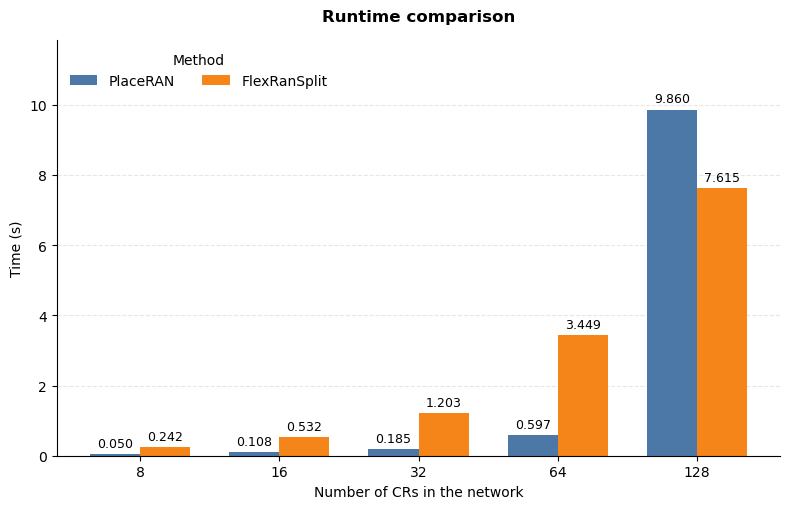

Đã lưu: /home/stu1/Code/Flex-split/FlexRanSplitProblem/results/comparison_figures/runtime_comparison.png


In [9]:
runtime_image = grouped_bar_chart(
    [item['placeran_runtime'] for item in rows],
    [item['flex_runtime'] for item in rows],
    title='Runtime comparison',
    ylabel='Time (s)',
    filename='runtime_comparison.png',
    value_format='.3f',
)

## Biểu đồ 2 - Số DRC được sử dụng

Số DRC là số giá trị `DRC` khác nhau trong nghiệm cuối cùng của network.

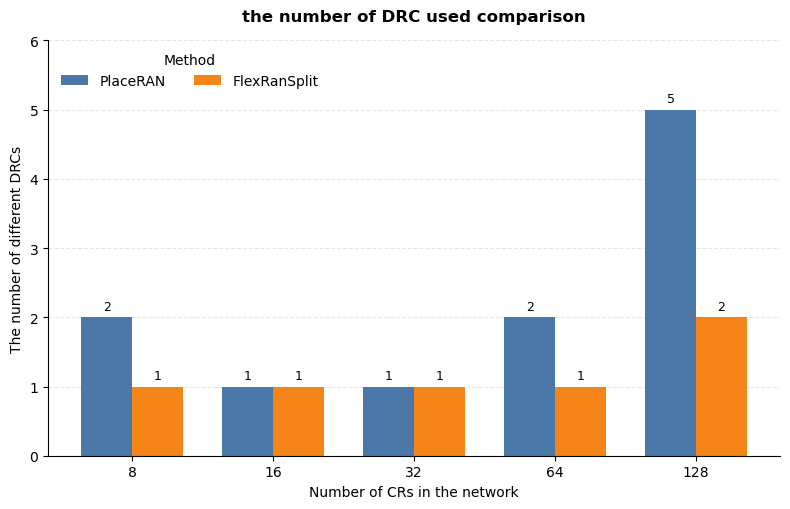

Đã lưu: /home/stu1/Code/Flex-split/FlexRanSplitProblem/results/comparison_figures/drc_count_comparison.png


In [10]:
drc_image = grouped_bar_chart(
    [item['placeran_drc_count'] for item in rows],
    [item['flex_drc_count'] for item in rows],
    title='the number of DRC used comparison',
    ylabel='The number of different DRCs',
    filename='drc_count_comparison.png',
    value_format='d',
)